In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Load the cleaned Kulgam dataset from Phase 1
df = pd.read_csv("cpgrams_kulgam_cleaned.csv")

# Ensure no NaN in cleaned text column
df["Grievance_Clean"] = df["Grievance_Clean"].fillna("")

print(f"Loaded {len(df)} records across {df['Pertaining_Department_Office'].nunique()} departments.")

Loaded 500 records across 13 departments.


In [2]:
df.head()

,Grievance_ID,Date,Grievance,Grievance_Category,Pertaining_Department_Office,Priority,Status,District,Tehsil,Submission_Channel,Relevant_Scheme_Guideline,Resolution_Days,Officer_Remarks,Is_Resolved,Grievance_Clean,Officer_Remarks_Clean
0,CPGRAMS-KLG-2023-0001,2023-11-20,"Choked open drains in Village Buchroo, Frisal ...",Development Related,Municipal Council / ULB Kulgam,Medium,Resolved,Kulgam,Frisal,JK-IGRAMS Portal,Swachh Bharat Mission (Urban) / Urban Infra,43.0,Municipal hopper vehicle assigned for daily do...,1,Choked open drains in Village Buchroo Frisal a...,Municipal hopper vehicle assigned for daily do...
1,CPGRAMS-KLG-2023-0002,2023-11-21,Doctor and paramedical staff are frequently ab...,Complaint Related,CMO (Health),High,Resolved,Kulgam,Devsar,Mobile App,NHM / Ayushman Bharat (PM-JAY SEHAT),20.0,BMO conducted inspection; biometric attendance...,1,Doctor and paramedical staff are frequently ab...,BMO conducted inspection biometric attendance ...
2,CPGRAMS-KLG-2023-0003,2023-11-22,Unlawful blockage of a common public pathway b...,Magisterial,ADC / ACR (Administration),Medium,Resolved,Kulgam,Frisal,CPGRAMS Web Portal,BNSS / Section 133 Public Nuisance & Magisteri...,45.0,Market checking squad fined erring shopkeepers...,1,Unlawful blockage of a common public pathway b...,Market checking squad fined erring shopkeepers...
3,CPGRAMS-KLG-2023-0004,2023-11-25,"To the Deputy Commissioner Kulgam, Frequent tr...",Others,ADC / ACR (Administration),Medium,Resolved,Kulgam,Pahloo,CPGRAMS Web Portal,General Public Service / Transport & Connectivity,34.0,Special Aadhaar update camp organized at Panch...,1,To the Deputy Commissioner Kulgam Frequent tra...,Special Aadhaar update camp organized at Panch...
4,CPGRAMS-KLG-2023-0005,2023-11-27,"Private school in Village Waltengoo Nar, Kund ...",Complaint Related,CEO (Education),Medium,Resolved,Kulgam,Devsar,CPGRAMS Web Portal,Samagra Shiksha / RTE Act,23.0,Subject teachers rationalized and deployed to ...,1,Private school in Village Waltengoo Nar Kund i...,Subject teachers rationalized and deployed to ...


In [23]:
X = df["Grievance_Clean"]
y_dept = df["Pertaining_Department_Office"]
y_prio = df["Priority"]

# Stratified 80/20 split to preserve department distribution in train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y_dept, test_size=0.20, random_state=42, stratify=y_dept
)

# Model 1 (Primary): TF-IDF + Logistic Regression
lr_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(stop_words="english", ngram_range=(1, 2), max_features=3000)),
    ("clf", LogisticRegression(max_iter=2000, C=2.0, random_state=42))
])

# Model 2 (Baseline Comparison): TF-IDF + Random Forest
rf_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(stop_words="english", ngram_range=(1, 2), max_features=3000)),
    ("clf", RandomForestClassifier(n_estimators=200, random_state=42))
])

# Train both models
lr_pipeline.fit(X_train, y_train)
rf_pipeline.fit(X_train, y_train)

# Train a lightweight Urgency/Priority predictor using the same architecture
X_tr_p, X_te_p, y_tr_p, y_te_p = train_test_split(
    X, y_prio, test_size=0.20, random_state=42, stratify=y_prio
)
priority_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(stop_words="english", ngram_range=(1, 2), max_features=3000)),
    ("clf", LogisticRegression(max_iter=10000, class_weight="balanced", random_state=42))
])
priority_pipeline.fit(X_tr_p, y_tr_p)

print("Training complete for Department Routing (LR & RF) and Priority Prediction (LR).")

Training complete for Department Routing (LR & RF) and Priority Prediction (LR).


In [24]:
# Predictions using logistic regression and random forest
y_pred_lr = lr_pipeline.predict(X_test)
y_pred_rf = rf_pipeline.predict(X_test)

acc_lr = accuracy_score(y_test, y_pred_lr)
acc_rf = accuracy_score(y_test, y_pred_rf)
acc_prio = accuracy_score(y_te_p, priority_pipeline.predict(X_te_p))

print(f"Department Routing Accuracy (Logistic Regression): {acc_lr:.2%}")
print(f"Department Routing Accuracy (Random Forest):       {acc_rf:.2%}")
print(f"Urgency/Priority Accuracy (Logistic Regression):   {acc_prio:.2%}\n")

print("=== Detailed Classification Report (Logistic Regression — Department Routing) ===")
print(classification_report(y_test, y_pred_lr, zero_division=0))

Department Routing Accuracy (Logistic Regression): 100.00%
Department Routing Accuracy (Random Forest):       99.00%
Urgency/Priority Accuracy (Logistic Regression):   47.00%

=== Detailed Classification Report (Logistic Regression — Department Routing) ===
                                          precision    recall  f1-score   support

                  ACD & BDOs (Rural Dev)       1.00      1.00      1.00         6
             AD FCS&CA (Food & Supplies)       1.00      1.00      1.00         5
              ADC / ACR (Administration)       1.00      1.00      1.00        26
                         CEO (Education)       1.00      1.00      1.00         6
                            CMO (Health)       1.00      1.00      1.00         6
Chief Horticulture / Agriculture Officer       1.00      1.00      1.00         6
                   DSWO (Social Welfare)       1.00      1.00      1.00         5
          Municipal Council / ULB Kulgam       1.00      1.00      1.00         7
   

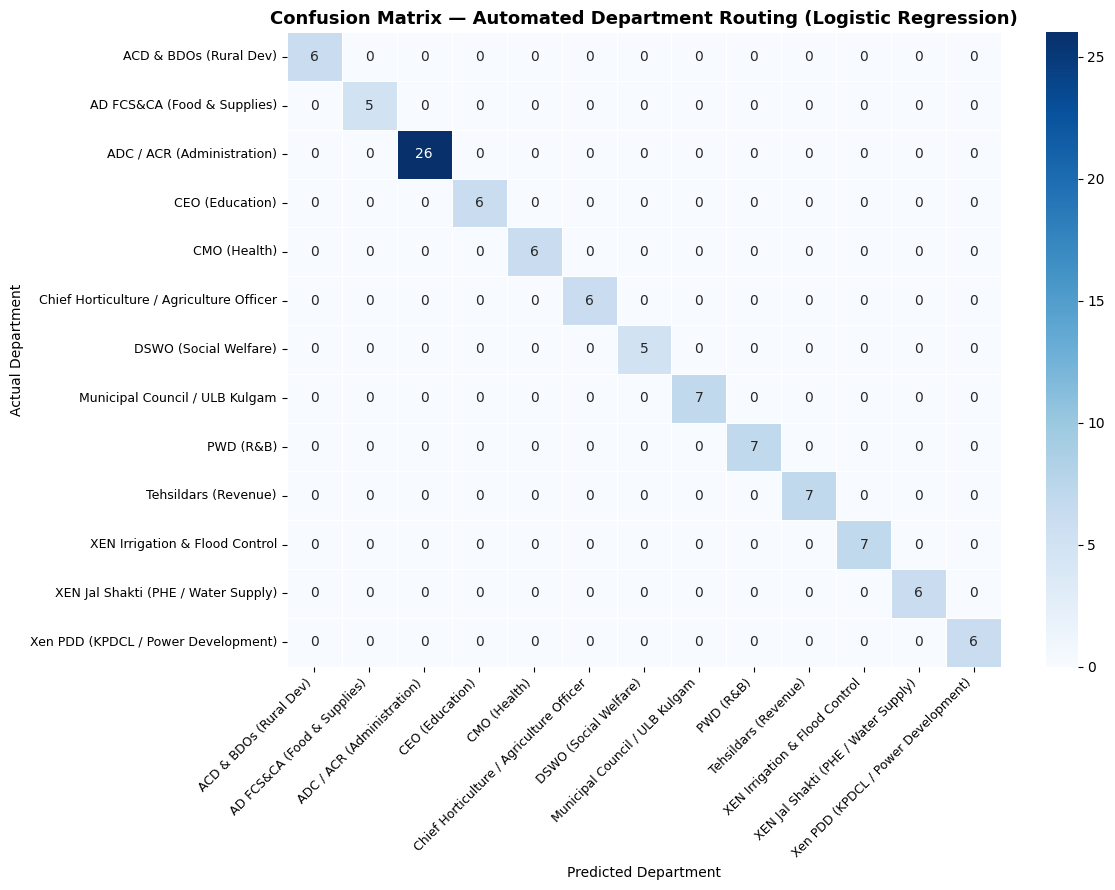

In [25]:
labels = sorted(y_dept.unique())
cm = confusion_matrix(y_test, y_pred_lr, labels=labels)

plt.figure(figsize=(12, 9))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels,
    linewidths=0.5
)
plt.title("Confusion Matrix — Automated Department Routing (Logistic Regression)", fontsize=13, fontweight="bold")
plt.xlabel("Predicted Department")
plt.ylabel("Actual Department")
plt.xticks(rotation=45, ha="right", fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()
plt.show()

In [26]:
# Test routing on new complaints
sample_complaints = [
    "The 100 KVA transformer in Village Bugam Yaripora burnt 5 days ago and villagers are without electricity.",
    "Our poor family in Manzgam DH Pora has still not received PMAY-G housing installment despite geo-tagging.",
    "Illegal sand and bajri mining is happening at night in Vishow Nallah near Redwani Qaimoh.",
    "My Land Mutation is still pending for many days",
    "There is safety threat to our children due to stray dogs in our locality"
]

print("=== Live Routing & Urgency Predictions ===")
for text in sample_complaints:
    pred_dept = lr_pipeline.predict([text])[0]
    dept_conf = lr_pipeline.predict_proba([text]).max()
    pred_prio = priority_pipeline.predict([text])[0]
    print(f"\nComplaint : {text}")
    print(f"Routed To : {pred_dept} (Confidence: {dept_conf:.1%})")
    print(f"Urgency   : {pred_prio}")



=== Live Routing & Urgency Predictions ===

Complaint : The 100 KVA transformer in Village Bugam Yaripora burnt 5 days ago and villagers are without electricity.
Routed To : Xen PDD (KPDCL / Power Development) (Confidence: 30.2%)
Urgency   : High

Complaint : Our poor family in Manzgam DH Pora has still not received PMAY-G housing installment despite geo-tagging.
Routed To : ACD & BDOs (Rural Dev) (Confidence: 32.1%)
Urgency   : High

Complaint : Illegal sand and bajri mining is happening at night in Vishow Nallah near Redwani Qaimoh.
Routed To : ADC / ACR (Administration) (Confidence: 42.3%)
Urgency   : Medium

Complaint : My Land Mutation is still pending for many days
Routed To : ADC / ACR (Administration) (Confidence: 20.9%)
Urgency   : High

Complaint : There is safety threat to our children due to stray dogs in our locality
Routed To : ADC / ACR (Administration) (Confidence: 23.6%)
Urgency   : Medium


# Title
Why Conventional ML Algorithm is Better in this Scenario?
## section
Here conventional model like logistic regression and Random Forest is used instead of using Deep Nueral Network or BERT 
because the data set is too small (just 500 rows) for a DNN/BERT,created from scratch, to generalize. In other words complex models 
like DNN/BERT would overfit on small dataset. Also conventional models require less computational power to train.